In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pickle
import glob

In [ ]:
from 

model = resnet18(pretrained=False)

In [4]:
df = pd.DataFrame(columns=['model', 'dataset', 'method', 'args', 'iter', 'acc@1'])

paths = glob.glob('./output/*/*/*')
for path in sorted(paths):
    if not os.path.isdir(path):
        continue

    model, dataset, method = path.split('/')[-3:]
    args = ', '.join(method.split('_')[1:])
    method = method.split('_')[0]
    acc1 = []
    acc5 = []

    for iter in os.listdir(path):
        if not os.path.exists(os.path.join(path, iter, 'results.pkl')):
            continue
        
        results = pickle.load(open(os.path.join(path, iter, 'results.pkl'), 'rb'))

        acc1.append(results['accuracy1'])
        acc5.append(results['accuracy5'])
        
    if len(acc1) > 0:
        df = df.append({
            'model': model,
            'dataset': dataset,
            'method': method,
            'args': args,
            'iter': len(acc1),
            'acc@1': f'{np.mean(acc1):.2f}±{np.std(acc1):.2f}',
        }, ignore_index=True)
        # print(path)
print(df)


             model        dataset    method   args iter       acc@1
0   conv2next-tiny       cifar100       snr  0.001    2  83.72±0.29
1   conv2next-tiny       cifar100       snr   0.01    2  83.41±0.08
2   conv2next-tiny       cifar100       snr    0.1    2  83.56±0.09
3   conv2next-tiny       cifar100       snr    1.0    3  83.18±0.46
4   conv2next-tiny       cifar100      snvr    0.1    1  83.10±0.00
5   conv2next-tiny       cifar100      snvr    1.0    1  82.69±0.00
6       eswin-tiny          stl10       snr   0.01    2  80.27±0.49
7         resnet18  tiny-imagenet  baseline           3  68.56±0.22
8         resnet18  tiny-imagenet        sn           2  68.62±0.16
9         resnet18  tiny-imagenet       snr   0.01    3  68.61±0.20
10        resnet18  tiny-imagenet      snvr           2  69.03±0.34
11        resnet18  tiny-imagenet        tb           2  67.97±0.01
12        resnet18  tiny-imagenet        wn           2  68.48±0.19


In [ ]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_list = fm.findSystemFonts(fontpaths=None, fontext='ttf')
f = [f.name for f in fm.fontManager.ttflist]
print(*f, sep='\n')

from matplotlib import rc

# matplotlib.use('PDF')
plt.rc('font', family='Nimbus Roman')

=== baseline ===


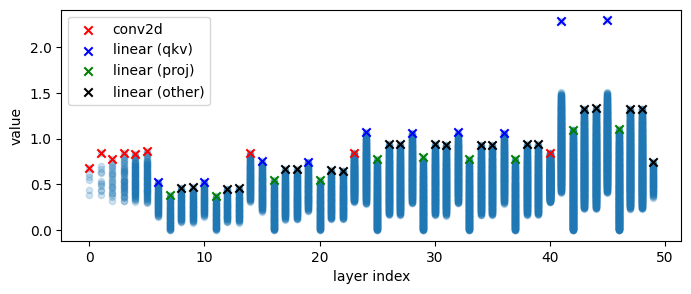

In [6]:
from torchvision.models import resnet18, resnet34
from models.eswin_transformer import ESwinTransformer
from models.conv2next import conv2next_tiny
from optimizer.snvr import calc_sn_uv

import torch.nn as nn
import torch

from math import ceil

titles = ['(a) WD', '(b) WN', '(c) SN', '(d) TB', '(e) SNR', '(f) SNVR(Ours)']
methods = ['baseline', 'wn', 'sn', 'tb',  'snr', 'snvr']

figs, axs = plt.subplots(ceil(len(methods)/2), 2, figsize=(16, ceil(len(methods)/2)*3))

for i, method in enumerate(methods):
    print(f'=== {method} ===')
    ckpt = torch.load(f'./output/conv2next-tiny/cifar100/{method}/0/ckpt_best.pt')
    
    model = conv2next_tiny(num_classes=100)
    # model = resnet34(num_classes=100)
    # model =    ESwinTransformer(
    #             img_size=128,
    #             patch_size=2,
    #             num_classes=101,
    #             embed_dim=96,
    #             depths=[2,2,4,2],
    #             num_heads=[3,6,12,24],
    #             window_size=4,
    #             mlp_ratio=2,
    #             )

    modules = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    modules = modules[1:-1]

    if method == 'wn':
        for m in modules:
            if hasattr(m, 'weight'):
                torch.nn.utils.weight_norm(m, name='weight', dim=0)
    elif method == 'sn':
        for m in modules:
            if hasattr(m, 'weight'):
                torch.nn.utils.spectral_norm(m, name='weight', n_power_iterations=1)
    model.load_state_dict(ckpt['model'], strict=True)

    dummy_input = torch.randn(2, 3, 32, 32)
    model.eval()
    model(dummy_input)


    modules = [m for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    modules = modules[1:-1]

    ax = axs.flatten()[i]

    for idx, module in enumerate(modules):
        if isinstance(module, nn.Conv2d):
            color = 'red'
            weight = module.weight.data
            weight = weight.view(weight.size(0), -1)
            # weight = weight.view(weight.size(0), weight.size(1), -1)
            # weight = weight.transpose(1, 2).transpose(0, 1)
        elif isinstance(module, nn.Linear):
            color = 'orange'
            weight = module.weight.data
        sn = torch.linalg.svd(weight).S.flatten()
        # print(weight.shape)
        # sn, _ = calc_sn_uv(weight, n_power=5)
        ax.scatter([idx]*len(sn), sn.cpu().numpy(), alpha=0.2, c='C0', s=20, marker='o')
        ax.scatter(idx, sn.max().cpu().numpy(), color=color, s=20, marker='o')
        idx += 1
    # plt.scatter([], [], color=color, marker='x', label=method)

    # plt.legend()
    ax.set_title(f'{titles[i]}', fontsize=20, loc='left', weight='bold', pad=10)
    ax.set_ylim(-1, 16)
    
    if i < len(methods)-2:
        ax.set_xticklabels([])
    else:
        ax.set_xlabel('Layer index', fontsize=20)

    if i % 2 == 1:
        ax.set_yticklabels([])
    elif i == 2:
        ax.set_ylabel('Singular value', fontsize=20)

    for y in np.arange(0, 16, 5):
        ax.axhline(y, linestyle='--', color='gray', alpha=0.5, zorder=-1)

    if i == 1:
        ax.scatter([], [], color='red', marker='o', label='Spectral norm (Conv2d)')
        ax.scatter([], [], color='orange', marker='o', label='Spectral norm (Linear)')
        ax.scatter([], [], color='C0', marker='o', label='Singular values')
        ax.legend(fontsize=15, loc='upper right')


plt.tight_layout()
plt.savefig('singular_distribution.pdf', bbox_inches='tight')
# plt.show()

In [52]:
import math
import weightwatcher as ww
import torch
from torchvision import models

model_name = 'resnet34'
datasets = ['cifar10', 'cifar100', 'tiny-imagenet', 'stl10', 'food101']
for dataset in datasets:
    dataset_path = f'./output/{model_name}/{dataset}'
    if not os.path.exists(dataset_path):
        continue
    for path in sorted(os.listdir(dataset_path)):
        if not os.path.exists(os.path.join(dataset_path, path, '0', 'ckpt_best.pt')):
            continue
        num_classes = 10 if dataset in ['cifar10', 'stl10'] else 100 if dataset == 'cifar100' else 200 if dataset == 'tiny-imagenet' else 101
        model = models.resnet34(num_classes=num_classes)
        model.conv1 = torch.nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        model.maxpool = torch.nn.Identity()

        ckpt = torch.load(os.path.join(dataset_path, path, '0', 'ckpt_best.pt'))
        model.load_state_dict(ckpt['model'], strict=False)

        watcher = ww.WeightWatcher(model=model)
        details = watcher.analyze(plot=False, layers=[])
        
        print(dataset, path, f'{details["alpha"].mean():.2f}')
    print()


AttributeError: module 'torch.linalg' has no attribute 'svdvals'